# 3.2 Household income and nursery fees: planning-area regression (H-b, fee side)

Do fees track neighbourhood income? This notebook regresses each planning area's median full-day
nursery fee (from 3.1) on its estimated median monthly household income (SingStat grouped counts,
median interpolated inside the median band). The fit is ordinary least squares with income in S$
thousands; inference is a two-sided permutation test for the Pearson and Spearman correlations
(49,999 permutations) and a paired bootstrap interval for the slope (20,000 resamples). A Cook's-distance
influence check shows how much the result depends on the few affluent central areas. The code is Daryl's `scripts/household_income_nursery_fee_regression.py`;
`prepare_data` and `ols_fit` are shared with 3.3 through `src/bt4015/regression.py`.

**Change from the script (2026-11-10).** The fee table is now the 2026 planning-area table from 3.1
(1,586 fees, 42 areas) instead of the 2021 one (1,363 fees, 38 areas). The income CSV covers 30
planning areas, so 30 areas are matched in both versions. Outputs go to the folder Daryl's 2026 run uses on `main`,
`output/household_income_nursery_fee_regression_2026/`.

**Changed 2026-11-13.** Matched Daryl's 11 Nov update of the script: the Theil-Sen robust slope was dropped
from the figure and the summary table. With most planning areas at the S$650 anchor fee the median pairwise
slope is exactly 0, which read as "no relationship" and was misleading next to the OLS; the Cook's-distance
refit keeps the influence check. Output folder renamed to the `_2026` name.

**Inputs**
- `output/spatial_autocorrelation_nursery_fee_planning_area_2026/planning_area_nursery_fee_moran.csv` (3.1).
- `data/ResidentHouseholdsIncomebyPlanningArea.csv` (SingStat, resident households by monthly income band and planning area).

**Outputs** (`output/household_income_nursery_fee_regression_2026/`)
- `planning_area_regression_data.csv` (30 areas with fitted fee, residual and Cook's distance), `regression_summary.csv` (metrics), `income_nursery_fee_regression.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bt4015.regression import INCOME_BANDS, ols_fit, prepare_data

INCOME_CSV = DATA / "ResidentHouseholdsIncomebyPlanningArea.csv"
NURSERY_CSV = OUT / "spatial_autocorrelation_nursery_fee_planning_area_2026" / "planning_area_nursery_fee_moran.csv"
OUT_DIR = OUT / "household_income_nursery_fee_regression_2026"   # Daryl's folder on main (11 Nov)
OUT_DIR.mkdir(parents=True, exist_ok=True)
PERMUTATIONS = 49_999     # two-sided permutation test for the correlations
BOOTSTRAP_SAMPLES = 20_000  # paired bootstrap resamples for the slope interval
SEED = 4015
BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e6e5e1"

## 1. Prepare the planning-area table

`prepare_data` estimates the median income of each planning area by linear interpolation inside the
band that contains the 50th percentile household (the open $20,000+ band is given the width of the band
before it; only Tanglin's estimate depends on this), then joins to the fee table on the upper-cased
name. Areas present in only one source are listed so the loss is visible.

In [2]:
# 1. Join estimated median income to median fee; keep the coverage report.
data, coverage = prepare_data(INCOME_CSV, NURSERY_CSV)
print(f"matched planning areas: {len(data)}")
print("income areas without a fee match:", ", ".join(coverage["income_without_fee"]) or "none")
print("fee areas without income data:", ", ".join(coverage["fee_without_income"]) or "none")
print(data[["planning_area_name", "median_income_range", "estimated_median_income_sgd", "median_fee_sgd", "centre_count"]]
      .round(0).to_string(index=False))

# 2. Model variables: income in S$ thousands (so the slope reads as S$ fee per S$1,000 income).
income_thousands = data["estimated_median_income_sgd"].to_numpy() / 1_000.0
midpoint_thousands = data["median_income_band_midpoint_sgd"].to_numpy() / 1_000.0
fees = data["median_fee_sgd"].to_numpy()

matched planning areas: 30
income areas without a fee match: none
fee areas without income data: CHANGI, MANDAI, MARINA SOUTH, MUSEUM, NEWTON, ORCHARD, ROCHOR, SELETAR, SINGAPORE RIVER, SOUTHERN ISLANDS, TENGAH, WESTERN WATER CATCHMENT
planning_area_name median_income_range  estimated_median_income_sgd  median_fee_sgd  centre_count
        Ang Mo Kio       $5,000-$5,999                       5606.0           650.0            54
             Bedok       $7,000-$7,999                       7029.0           770.0            91
            Bishan     $10,000-$10,999                      10033.0           650.0            38
       Bukit Batok       $7,000-$7,999                       7635.0           650.0            58
       Bukit Merah       $5,000-$5,999                       5652.0           650.0            43
     Bukit Panjang       $8,000-$8,999                       8002.0           650.0            44
       Bukit Timah     $15,000-$17,499                      17469.0          1

## 2. Ordinary least squares

The headline slope, with the band-midpoint version of income as a sensitivity (it checks that the
interpolation step does not drive the result).

In [3]:
# 1. OLS on interpolated income (main model) and on band midpoints (sensitivity).
model = ols_fit(income_thousands, fees)
midpoint_model = ols_fit(midpoint_thousands, fees)
print(f"median fee = {model['intercept']:,.1f} + {model['slope']:,.1f} x income (S$ thousands)")
print(f"R-squared = {model['r_squared']:.3f}; residual standard error = S${model['rmse']:,.1f}")
print(f"midpoint sensitivity: slope {midpoint_model['slope']:,.1f}, R-squared {midpoint_model['r_squared']:.3f}")

median fee = -46.4 + 113.9 x income (S$ thousands)
R-squared = 0.626; residual standard error = S$352.7
midpoint sensitivity: slope 108.8, R-squared 0.611


## 3. Permutation tests for the correlations

With 30 areas and a skewed outcome (most HDB towns at S$610-650, a few central areas above S$2,000),
a permutation p-value is safer than the t-test. Spearman is reported alongside Pearson because the
income data are grouped.

In [4]:
def correlation(x, y):
    """Pearson correlation of two arrays."""
    return float(np.corrcoef(x, y)[0, 1])


def rank_values(values):
    """Average ranks, for the Spearman correlation."""
    return pd.Series(values).rank(method="average").to_numpy(dtype=float)


def permutation_p_values(x, y, permutations, seed):
    """Two-sided permutation p-values for the Pearson and Spearman correlations of x and y."""
    pearson = correlation(x, y)
    x_rank = rank_values(x)
    y_rank = rank_values(y)
    spearman = correlation(x_rank, y_rank)
    rng = np.random.default_rng(seed)
    pearson_extreme = 0
    spearman_extreme = 0
    for _ in range(permutations):
        permuted = rng.permutation(len(y))
        pearson_extreme += abs(correlation(x, y[permuted])) >= abs(pearson)
        spearman_extreme += abs(correlation(x_rank, y_rank[permuted])) >= abs(spearman)
    pearson_p = (pearson_extreme + 1) / (permutations + 1)
    spearman_p = (spearman_extreme + 1) / (permutations + 1)
    return pearson, pearson_p, spearman, spearman_p


# 1. Shuffle fees against incomes 49,999 times; count |r| at least as large as observed.
pearson, pearson_p, spearman, spearman_p = permutation_p_values(income_thousands, fees, PERMUTATIONS, SEED)
print(f"Pearson r = {pearson:.4f}, permutation p = {pearson_p:.5f}")
print(f"Spearman rho = {spearman:.4f}, permutation p = {spearman_p:.5f}")

Pearson r = 0.7912, permutation p = 0.00006
Spearman rho = 0.3335, permutation p = 0.07196


## 4. Bootstrap interval for the slope

Paired resampling of the 30 areas (seed 4016, as in the script) gives a percentile interval for the
slope and a band for the fitted line.

In [5]:
def bootstrap_coefficients(x, y, samples, seed):
    """Paired bootstrap of (intercept, slope) for the simple regression of y on x."""
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(x), size=(samples, len(x)))
    bx = x[indices]
    by = y[indices]
    x_mean = bx.mean(axis=1)
    y_mean = by.mean(axis=1)
    denominator = ((bx - x_mean[:, None]) ** 2).sum(axis=1)
    valid = denominator > 0
    slope = ((bx - x_mean[:, None]) * (by - y_mean[:, None])).sum(axis=1)[valid]
    slope = slope / denominator[valid]
    intercept = y_mean[valid] - slope * x_mean[valid]
    return intercept, slope


# 1. 20,000 paired resamples; 2.5 and 97.5 percentiles of the slope.
boot_intercept, boot_slope = bootstrap_coefficients(income_thousands, fees, BOOTSTRAP_SAMPLES, SEED + 1)
slope_ci = np.percentile(boot_slope, [2.5, 97.5])
print(f"slope 95% bootstrap interval: S${slope_ci[0]:,.1f} to S${slope_ci[1]:,.1f} per S$1,000 "
      f"({len(boot_slope):,} valid resamples)")

slope 95% bootstrap interval: S$70.9 to S$142.1 per S$1,000 (20,000 valid resamples)


## 5. Influence check

Most areas sit on the anchor-operator fee regardless of income, so the OLS slope is carried by the
affluent central areas. Cook's distance names them; the model is refitted without the most influential
one. (The Theil-Sen robust slope that used to open this section was dropped on 2026-11-13, see the header.)


In [6]:
# 1. Cook's distance: the five most influential areas and the 4/n guide.
cooks = np.asarray(model["cooks_distance"])
order = np.argsort(cooks)[::-1][:5]
print(f"Cook's distance guide 4/n = {4 / len(data):.3f}; most influential areas:")
for index in order:
    print(f"  {data.loc[index, 'planning_area_name']:<16} income S${data.loc[index, 'estimated_median_income_sgd']:,.0f}, "
          f"fee S${data.loc[index, 'median_fee_sgd']:,.0f}, Cook's D {cooks[index]:.3f}")

# 2. Refit without the single most influential area.
top_influence_index = int(np.argmax(cooks))
keep = np.arange(len(data)) != top_influence_index
model_without_top_influence = ols_fit(income_thousands[keep], fees[keep])
top_influence_name = str(data.loc[top_influence_index, "planning_area_name"])
print(f"\nwithout {top_influence_name}: slope {model_without_top_influence['slope']:,.1f}, "
      f"R-squared {model_without_top_influence['r_squared']:.3f}")

Cook's distance guide 4/n = 0.133; most influential areas:
  Downtown Core    income S$15,748, fee S$2,350, Cook's D 0.269
  Outram           income S$3,314, fee S$975, Cook's D 0.214
  Marine Parade    income S$8,886, fee S$1,860, Cook's D 0.115
  Novena           income S$9,258, fee S$1,680, Cook's D 0.065
  Queenstown       income S$6,554, fee S$1,254, Cook's D 0.062

without Downtown Core: slope 103.3, R-squared 0.583


## 6. Figure: income against fee with the OLS line and bootstrap band


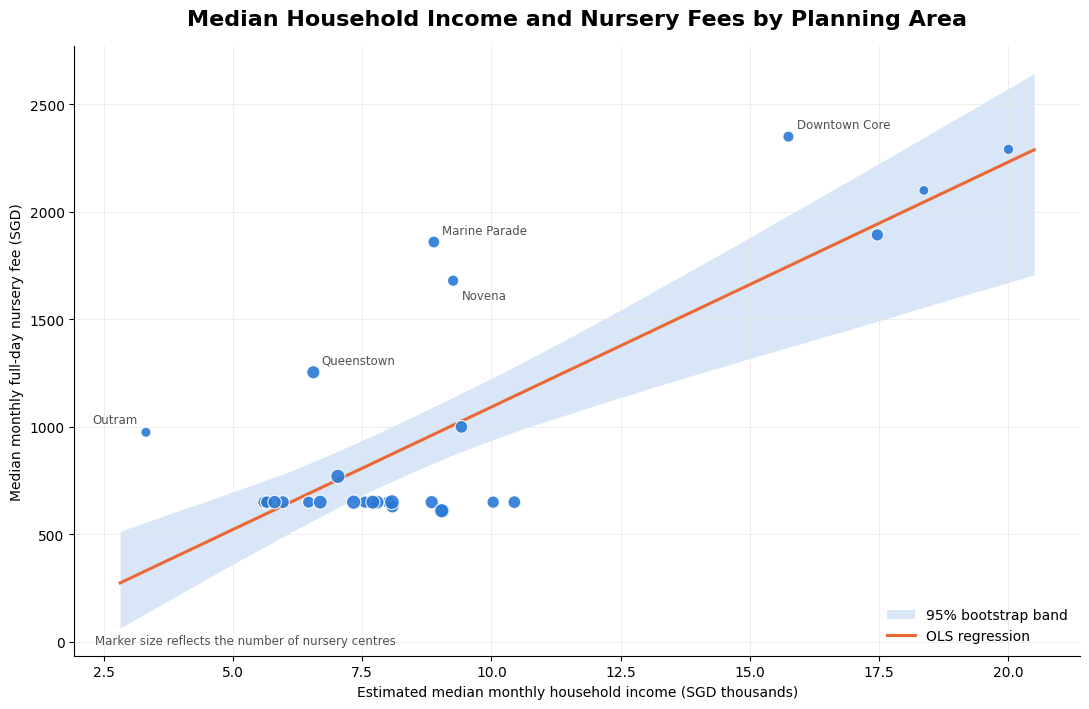

In [7]:
x = income_thousands
y = fees
x_grid = np.linspace(max(0, x.min() - 0.5), x.max() + 0.5, 240)
regression = model["intercept"] + model["slope"] * x_grid
boot_prediction = boot_intercept[:, None] + boot_slope[:, None] * x_grid[None, :]
lower, upper = np.percentile(boot_prediction, [2.5, 97.5], axis=0)
sizes = 30 + 8 * np.sqrt(data["centre_count"].to_numpy())

fig, ax = plt.subplots(figsize=(11, 7.2))
ax.fill_between(x_grid, lower, upper, color=BLUE, alpha=0.18, linewidth=0, label="95% bootstrap band")
ax.plot(x_grid, regression, color=ORANGE, linewidth=2.2, label="OLS regression")
ax.scatter(x, y, s=sizes, color=BLUE, edgecolor="white", linewidth=0.8, alpha=0.9, zorder=3)
top_influence = np.argsort(cooks)[-5:]
offsets = [(6, 6), (6, -13), (6, 6), (-6, 7), (6, 6)]
for index, offset in zip(top_influence, offsets):
    ax.annotate(data.loc[index, "planning_area_name"], (x[index], y[index]), xytext=offset,
                textcoords="offset points", fontsize=8.5, ha="right" if offset[0] < 0 else "left", color=INK2)
ax.set_title("Median Household Income and Nursery Fees by Planning Area", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Estimated median monthly household income (SGD thousands)")
ax.set_ylabel("Median monthly full-day nursery fee (SGD)")
ax.grid(axis="both", color=GRID, linewidth=0.7, alpha=0.65)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
ax.text(0.02, 0.02, "Marker size reflects the number of nursery centres", transform=ax.transAxes, ha="left",
        fontsize=8.5, color=INK2)
fig.tight_layout()
fig.savefig(OUT_DIR / "income_nursery_fee_regression.png", dpi=240, facecolor="white")
plt.show()

## 7. Diagnostics: residuals against fitted values and Cook's distance

Daryl's script defines this figure but does not save it; it is shown here for the record.

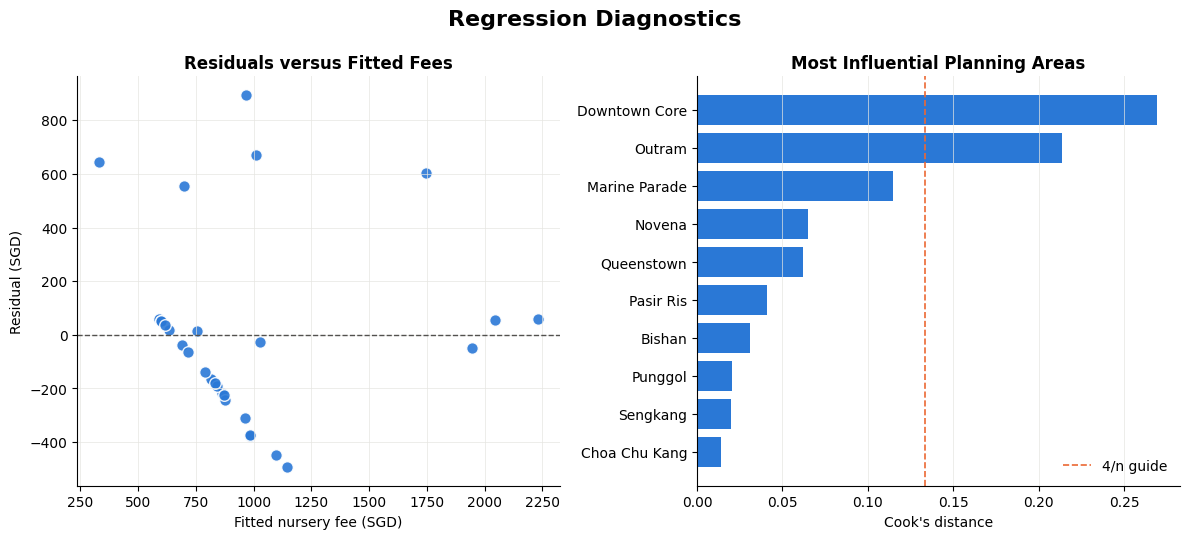

In [8]:
fitted = np.asarray(model["fitted"])
residual = np.asarray(model["residual"])
names = data["planning_area_name"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
axes[0].scatter(fitted, residual, color=BLUE, edgecolor="white", s=70, alpha=0.9)
axes[0].axhline(0, color=INK2, linestyle="--", linewidth=1)
axes[0].set_title("Residuals versus Fitted Fees", fontweight="bold")
axes[0].set_xlabel("Fitted nursery fee (SGD)")
axes[0].set_ylabel("Residual (SGD)")
axes[0].grid(color=GRID, linewidth=0.7, alpha=0.7)
shown = np.argsort(cooks)[::-1][:10][::-1]
axes[1].barh(names[shown], cooks[shown], color=BLUE)
axes[1].axvline(4 / len(data), color=ORANGE, linestyle="--", linewidth=1.2, label="4/n guide")
axes[1].set_title("Most Influential Planning Areas", fontweight="bold")
axes[1].set_xlabel("Cook's distance")
axes[1].legend(frameon=False, loc="lower right")
axes[1].grid(axis="x", color=GRID, linewidth=0.7, alpha=0.7)
for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
fig.suptitle("Regression Diagnostics", fontsize=16, fontweight="bold", y=0.99)
fig.tight_layout()
plt.show()

## 8. Write the tables

`regression_summary.csv` holds every statistic above; `planning_area_regression_data.csv` adds the fitted
fee, residual and Cook's distance to each area (3.3 recomputes the OLS from the same inputs).

In [9]:
data["fitted_median_fee_sgd"] = np.asarray(model["fitted"])
data["residual_sgd"] = np.asarray(model["residual"])
data["cooks_distance"] = cooks
data.to_csv(OUT_DIR / "planning_area_regression_data.csv", index=False)

result_rows = [
    ("matched_planning_areas", len(data)),
    ("intercept_sgd", model["intercept"]),
    ("slope_sgd_per_1000_income", model["slope"]),
    ("slope_bootstrap_ci_95_low", slope_ci[0]),
    ("slope_bootstrap_ci_95_high", slope_ci[1]),
    ("r_squared", model["r_squared"]),
    ("residual_standard_error_sgd", model["rmse"]),
    ("pearson_r", pearson),
    ("pearson_permutation_p_two_sided", pearson_p),
    ("spearman_rho", spearman),
    ("spearman_permutation_p_two_sided", spearman_p),
    ("midpoint_sensitivity_slope", midpoint_model["slope"]),
    ("midpoint_sensitivity_r_squared", midpoint_model["r_squared"]),
    ("slope_excluding_most_influential_area", model_without_top_influence["slope"]),
    ("r_squared_excluding_most_influential_area", model_without_top_influence["r_squared"]),
]
summary = pd.DataFrame(result_rows, columns=["metric", "value"])
summary.to_csv(OUT_DIR / "regression_summary.csv", index=False)
print(summary.to_string(index=False))
print(f"\nwritten to {OUT_DIR.relative_to(ROOT)}/: planning_area_regression_data.csv ({len(data)} rows), "
      f"regression_summary.csv ({len(summary)} rows), income_nursery_fee_regression.png")

                                   metric      value
                   matched_planning_areas  30.000000
                            intercept_sgd -46.382099
                slope_sgd_per_1000_income 113.897154
                slope_bootstrap_ci_95_low  70.912415
               slope_bootstrap_ci_95_high 142.130524
                                r_squared   0.625978
              residual_standard_error_sgd 352.681444
                                pearson_r   0.791187
          pearson_permutation_p_two_sided   0.000060
                             spearman_rho   0.333495
         spearman_permutation_p_two_sided   0.071960
               midpoint_sensitivity_slope 108.818423
           midpoint_sensitivity_r_squared   0.611352
    slope_excluding_most_influential_area 103.274628
r_squared_excluding_most_influential_area   0.582827

written to output/household_income_nursery_fee_regression_2026/: planning_area_regression_data.csv (30 rows), regression_summary.csv (15 rows), income_